# 03 · Models, validation over time and explanations

With the feature set from notebook 02 fixed, this notebook asks:

1. **Is the model leaning on the calendar?** A check prompted by notebook 01.
2. **Which gradient-boosting library?** LightGBM, XGBoost and CatBoost are the three
   standard choices. They differ in how they grow trees and handle categories.
3. **Does blending them help?**
4. **How good is the final model** on the untouched test month?
5. **How fast does a model go stale**, and how often should it be retrained?
6. **Why does it flag a transaction?** With named features, SHAP explanations finally
   say something an analyst can use.

In [1]:
import subprocess
import sys
import time
import warnings

import catboost as cb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_auc_score

from fraudkit import ieee
from fraudkit.data import ROOT
from fraudkit.metrics import bootstrap_ci, paired_bootstrap_diff, recall_at_alert_rate
from fraudkit.plotting import CLASS_COLORS, INK_2, MUTED, SEQUENTIAL, SERIES, finish, label_bars, set_style

set_style()
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.4f}".format)
TRAIN_END, VAL_END = 120, 150
SEED = 0

/home/newf/projects/fraud-detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Features and splits

`ieee.cache_model_matrix` (built on `build_features`) reproduces notebook 02's pruned set: raw columns (with normalised D
columns and the 130 non-redundant V columns), frequency encodings, and the
confirmed-fraud count under a 30-day label delay. The amount/time and user-history
groups were redundant there, so they are left out. One change from notebook 02, `D3`
kept raw, is justified in section 2.

Frequency encodings are fitted on the training period. For the final model, retrained
on train + validation, a second set is fitted on that longer period.

In [2]:
# Feature building peaks above 2 GB, so it runs in a separate process that writes a float32
# matrix to disk. This notebook then opens it memory-mapped: pages are read on demand and,
# being backed by the file, can be dropped by the OS under memory pressure (7 GB machine).
CACHE = ROOT / "data" / "processed" / "ieee_model"
if not (CACHE / "X.npy").exists():
    subprocess.run([sys.executable, "-m", "fraudkit.ieee", str(CACHE)], check=True)
X, meta, info = ieee.load_feature_matrix(CACHE)
FEATURES, COLUMNS, cat_pos = info["features"], info["columns"], info["cat_pos"]
CAT_NAMES = {c: np.asarray(v) for c, v in info["categories"].items()}   # to show names in SHAP plots
y = meta.isFraud.values.astype(np.int8)

n_tr = int((meta.day < TRAIN_END).sum())
n_va = int((meta.day < VAL_END).sum())
TR, VA, TE = slice(0, n_tr), slice(n_tr, n_va), slice(n_va, len(y))
NF = len(FEATURES)            # the first NF columns use training-period encodings
F = list(range(NF))
CAT = [i for i in cat_pos if i < NF]
print(f"{len(FEATURES)} features ({len(CAT)} categorical); matrix {X.nbytes / 1e9:.2f} GB")
print(f"train {n_tr:,} rows · validation {n_va - n_tr:,} · test {len(y) - n_va:,}")

232 features (31 categorical); matrix 0.57 GB
train 410,601 rows · validation 85,303 · test 94,636


## 2. A calendar feature in disguise

Notebook 01's adversarial validation found that normalised `D3n` (with `D1n`) almost
perfectly reveals *when* a transaction happened. `D3` counts days since the card's
**previous** transaction, so day − D3 is simply a recent date. Notebook 02 normalised all
D columns together and never tested D3 on its own. A model that leans on a disguised date
can look fine on the next month and decay faster afterwards.

Three variants, each trained with two seeds on months 1–4 and scored on month 5:

In [3]:
LGB_BASE = dict(objective="binary", learning_rate=0.05, num_leaves=127, min_data_in_leaf=100,
                bagging_fraction=0.8, bagging_freq=1, feature_fraction=0.5, lambda_l2=1.0,
                max_cat_to_onehot=8, cat_smooth=20, verbose=-1, num_threads=12)
d3_variants = {
    "D3 raw (days since previous)": FEATURES,
    "D3n (date of previous, notebook 02)": [("D3n" if f == "D3" else f) for f in FEATURES],
    "D3 dropped": [f for f in FEATURES if f != "D3"],
}
d3_rows = {}
for name, feats in d3_variants.items():
    idx = [COLUMNS.index(f) for f in feats]
    cats = [i for i, f in enumerate(feats) if COLUMNS.index(f) in cat_pos]
    seeds = []
    for seed in (0, 1):
        b = lgb.train({**LGB_BASE, "seed": seed},
                      lgb.Dataset(X[:n_tr][:, idx], y[:n_tr], categorical_feature=cats), 1600)
        seeds.append(average_precision_score(y[n_tr:n_va], b.predict(X[n_tr:n_va][:, idx])))
        del b
    d3_rows[name] = {"PR-AUC (mean of 2 seeds)": np.mean(seeds), "seed 0": seeds[0], "seed 1": seeds[1]}
    ieee.release_memory()
pd.DataFrame(d3_rows).T

,PR-AUC (mean of 2 seeds),seed 0,seed 1
D3 raw (days since previous),0.7185,0.7184,0.7186
"D3n (date of previous, notebook 02)",0.7201,0.7200,0.7203
D3 dropped,0.7200,0.7159,0.7241


**Reading it.** The three variants tie: the differences are about the size of the gap
between two seeds of the same model. On the next month, the disguised date neither helps
nor hurts. A tie goes to the principled choice: **D3 stays raw**. "Days since the
previous transaction" means the same thing in any month, while a date only means
something relative to the training period. (Keeping D5, D7 and D13 raw too was also
tested during development; it scored slightly lower, so they stay normalised.)

This is the kind of check explainability prompts. In an earlier version of this notebook,
SHAP ranked `D3n` as the second most important feature, which is what sent us back to
notebook 01's drift result.

## 3. Three gradient-boosting libraries

All three build an ensemble of decision trees, each tree correcting the errors of the
previous ones. They differ in the details:

| | LightGBM | XGBoost | CatBoost |
|---|---|---|---|
| Tree growth | leaf-wise: split the leaf with the largest gain | level-wise (depth-limited) by default | **symmetric** (oblivious) trees: the same split across a whole level |
| Categoricals | native, optimal split over category groups | native (`enable_categorical`) | **ordered target statistics**: encodes categories with the target, computed in a way that avoids leakage |
| Typical strength | speed on large data | mature, robust | categorical-heavy data, little tuning |

Each model trains on months 1–4 with **early stopping** on month 5: training stops once
validation PR-AUC hasn't improved for 300 rounds. PR-AUC on ~3,000 frauds is noisy, and
a shorter patience can stop on a temporary plateau. Month 5 is used for model selection,
so its scores are slightly optimistic. That is why month 6 exists.

In [4]:
X_tr, X_va, X_te = X[TR, :NF], X[VA, :NF], X[TE, :NF]   # views, no copies
y_tr, y_va, y_te = y[TR], y[VA], y[TE]
results, val_scores, fitted = {}, {}, {}


def record(name, scores, minutes, rounds):
    pr, lo, hi = bootstrap_ci(average_precision_score, y_va, scores, n_boot=300)
    results[name] = {"PR-AUC": pr, "lo": lo, "hi": hi, "ROC-AUC": roc_auc_score(y_va, scores),
                     "rounds": rounds, "train minutes": minutes}
    val_scores[name] = scores
    print(f"{name:10s} PR-AUC {pr:.4f} [{lo:.4f}, {hi:.4f}]  {rounds} rounds, {minutes:.1f} min")


# LightGBM
t = time.time()
LGB_PARAMS = {**LGB_BASE, "metric": "average_precision", "seed": SEED}
dtr = lgb.Dataset(X_tr, y_tr, feature_name=FEATURES, categorical_feature=CAT, free_raw_data=False)
dva = lgb.Dataset(X_va, y_va, reference=dtr)
booster = lgb.train(LGB_PARAMS, dtr, 3000, valid_sets=[dva],
                    callbacks=[lgb.early_stopping(300, verbose=False)])
fitted["LightGBM"] = booster
record("LightGBM", booster.predict(X_va, num_iteration=booster.best_iteration),
       (time.time() - t) / 60, booster.best_iteration)
del dtr, dva
ieee.release_memory()

LightGBM   PR-AUC 0.7221 [0.7057, 0.7353]  2960 rounds, 2.1 min


In [5]:
# XGBoost: QuantileDMatrix bins the data once, without keeping a second full copy.
t = time.time()
ftypes = ["c" if i in CAT else "q" for i in F]
qtr = xgb.QuantileDMatrix(X_tr, y_tr, feature_types=ftypes, enable_categorical=True, max_bin=256)
qva = xgb.QuantileDMatrix(X_va, y_va, feature_types=ftypes, enable_categorical=True, ref=qtr)
XGB_PARAMS = dict(objective="binary:logistic", eval_metric="aucpr", tree_method="hist", eta=0.05,
                  max_depth=9, min_child_weight=5, subsample=0.8, colsample_bytree=0.5,
                  reg_lambda=1.0, max_cat_to_onehot=8, seed=SEED, nthread=12)
bst = xgb.train(XGB_PARAMS, qtr, 3000, evals=[(qva, "val")], early_stopping_rounds=300, verbose_eval=False)
record("XGBoost", bst.predict(qva, iteration_range=(0, bst.best_iteration + 1)),
       (time.time() - t) / 60, bst.best_iteration + 1)
del qtr, qva, bst   # only its validation scores are needed from here on
ieee.release_memory()

XGBoost    PR-AUC 0.7057 [0.6893, 0.7186]  912 rounds, 2.3 min


In [6]:
# CatBoost needs categoricals as integers or strings, not floats. Indexing a small array of
# shared string objects by the category codes keeps this cheap: each cell is a pointer.
def catboost_pool(Xp, yp=None):
    num = [i for i in F if i not in CAT]
    vocab_size = int(np.nanmax(X[:, CAT])) + 2
    vocab = np.array([str(i) for i in range(vocab_size - 1)] + ["NA"], dtype=object)
    codes = Xp[:, CAT]
    codes = np.where(np.isnan(codes), vocab_size - 1, codes).astype(np.int32)
    data = cb.FeaturesData(num_feature_data=np.ascontiguousarray(Xp[:, num]),
                           cat_feature_data=vocab[codes],
                           num_feature_names=[FEATURES[i] for i in num],
                           cat_feature_names=[FEATURES[i] for i in CAT])
    return cb.Pool(data, label=yp)


t = time.time()
ptr, pva = catboost_pool(X_tr, y_tr), catboost_pool(X_va, y_va)
cbm = cb.CatBoostClassifier(iterations=3000, learning_rate=0.08, depth=8, l2_leaf_reg=3,
                            eval_metric="PRAUC", od_type="Iter", od_wait=300, max_ctr_complexity=1,
                            border_count=64, random_seed=SEED, thread_count=12, verbose=False)
cbm.fit(ptr, eval_set=pva, use_best_model=True)
record("CatBoost", cbm.predict_proba(pva)[:, 1], (time.time() - t) / 60, cbm.get_best_iteration() + 1)
del ptr, pva, cbm
ieee.release_memory()

CatBoost   PR-AUC 0.6947 [0.6770, 0.7102]  1710 rounds, 5.4 min


## 4. Blending

The three libraries make partly different mistakes, so averaging can help. We average
**ranks** rather than probabilities, because their probability scales differ and a rank
average is insensitive to that.

In [7]:
blend = np.mean([rankdata(val_scores[m]) for m in ["LightGBM", "XGBoost", "CatBoost"]], axis=0)
record("Blend (rank avg.)", blend / len(blend), 0.0, 0)
res = pd.DataFrame(results).T
best_single = res.drop("Blend (rank avg.)")["PR-AUC"].astype(float).idxmax()
gain = paired_bootstrap_diff(average_precision_score, y_va, val_scores[best_single], blend)
print(f"blend − {best_single}: {gain[0]:+.4f}  (95 % CI {gain[1]:+.4f} to {gain[2]:+.4f})")
res

Blend (rank avg.) PR-AUC 0.7205 [0.7049, 0.7337]  0 rounds, 0.0 min


blend − LightGBM: -0.0016  (95 % CI -0.0056 to +0.0027)


,PR-AUC,lo,hi,ROC-AUC,rounds,train minutes
LightGBM,0.7221,0.7057,0.7353,0.9417,"2,960.0000",2.0544
XGBoost,0.7057,0.6893,0.7186,0.9404,912.0000,2.3448
CatBoost,0.6947,0.6770,0.7102,0.9393,"1,710.0000",5.3734
Blend (rank avg.),0.7205,0.7049,0.7337,0.9463,0.0000,0.0000


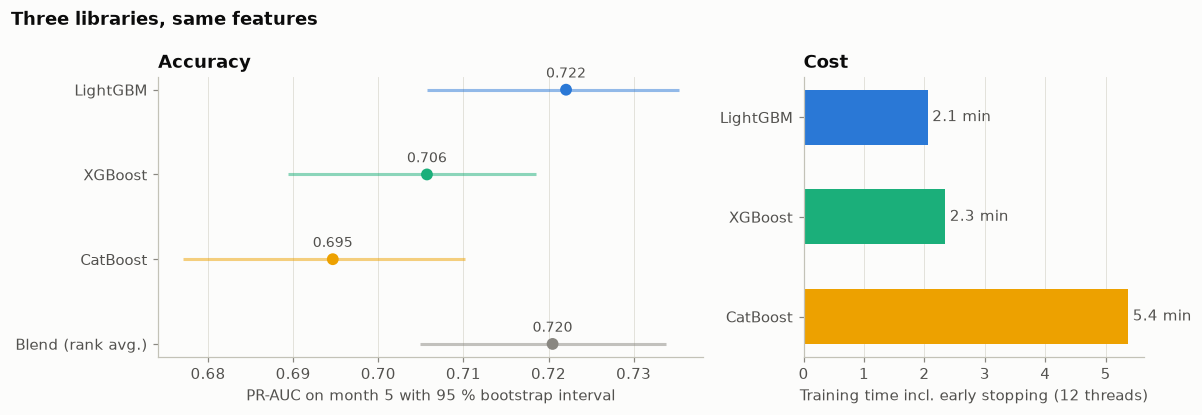

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
names = list(res.index)
colors = [SERIES[0], SERIES[2], SERIES[3], MUTED]
yp = np.arange(len(names))[::-1]
ax.hlines(yp, res["lo"].astype(float), res["hi"].astype(float), color=colors, lw=2, alpha=0.5)
ax.scatter(res["PR-AUC"].astype(float), yp, color=colors, s=60, zorder=3, edgecolor="white")
for yy, v in zip(yp, res["PR-AUC"].astype(float)):
    ax.annotate(f"{v:.3f}", (v, yy), xytext=(0, 8), textcoords="offset points", ha="center",
                fontsize=9, color=INK_2)
ax.set_yticks(yp, names); ax.grid(axis="y", visible=False)
ax.set_xlabel("PR-AUC on month 5 with 95 % bootstrap interval")
ax.set_title("Accuracy")
ax = axes[1]
singles = res.drop("Blend (rank avg.)")
bars = ax.barh(singles.index[::-1], singles["train minutes"].astype(float)[::-1], color=colors[:3][::-1], height=0.55)
label_bars(ax, bars, fmt="{:.1f} min", horizontal=True)
ax.set_xlabel("Training time incl. early stopping (12 threads)")
ax.set_title("Cost"); ax.grid(axis="y", visible=False)
fig.suptitle("Three libraries, same features", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.**
* **LightGBM leads** (0.722) and is also the fastest. XGBoost (0.706) and CatBoost (0.695)
  trail by more than their noise. LightGBM's best round (2,960) is close to the 3,000-round
  cap, so a little more may be available.
* **Fairness caveat:** the hyperparameters were developed with LightGBM in notebook 02.
  XGBoost and CatBoost got sensible but untuned settings, so this is not a verdict on the
  libraries in general. It is a verdict on *this pipeline with this budget*.
* **Blending doesn't help here**: −0.002, with an interval that includes zero. Blends
  pay off when members are comparably strong and make different mistakes. Here the two
  weaker models mostly dilute the best one. One model also means simpler monitoring and
  explanations, so **LightGBM goes forward alone**.

## 5. Final evaluation on the test month

The production recipe: retrain on **everything available** (months 1–5) with the
number of rounds found by early stopping, scaled up by the extra data, then score month 6
once. Frequency encodings are refitted on months 1–5 as well.

To quantify the value of retraining, we also score month 6 with the model trained on
months 1–4 only.

In [9]:
FINAL_COLS = [COLUMNS.index(f"{f}_final") if f.endswith("_freq") else i for i, f in enumerate(FEATURES)]
X_trva_final = X[0:n_va][:, FINAL_COLS]
X_te_final = X[TE][:, FINAL_COLS]
rounds = int(fitted["LightGBM"].best_iteration * n_va / n_tr)
t = time.time()
d_final = lgb.Dataset(X_trva_final, y[:n_va], feature_name=FEATURES, categorical_feature=CAT).construct()
del X_trva_final   # the binned Dataset is all LightGBM needs
ieee.release_memory()
final = lgb.train({k: v for k, v in LGB_PARAMS.items() if k != "metric"}, d_final, rounds)
del d_final
print(f"final LightGBM: {rounds} rounds on months 1–5, {(time.time() - t) / 60:.1f} min")
test_final = final.predict(X_te_final)
test_stale = fitted["LightGBM"].predict(X_te, num_iteration=fitted["LightGBM"].best_iteration)
ieee.release_memory()

rows = {}
for name, s in [("retrained on months 1–5", test_final), ("trained on months 1–4 only", test_stale)]:
    pr, lo, hi = bootstrap_ci(average_precision_score, y_te, s, n_boot=300)
    rows[name] = {"PR-AUC": pr, "95 % CI": f"{lo:.3f}–{hi:.3f}", "ROC-AUC": roc_auc_score(y_te, s),
                  "recall @ 2 % reviewed": recall_at_alert_rate(y_te, s, 0.02),
                  "recall @ 5 % reviewed": recall_at_alert_rate(y_te, s, 0.05)}
test_table = pd.DataFrame(rows).T
test_table

final LightGBM: 3574 rounds on months 1–5, 2.4 min


,PR-AUC,95 % CI,ROC-AUC,recall @ 2 % reviewed,recall @ 5 % reviewed
retrained on months 1–5,0.6867,0.671–0.700,0.9379,0.5009,0.6956
trained on months 1–4 only,0.6128,0.598–0.627,0.9215,0.4573,0.6255


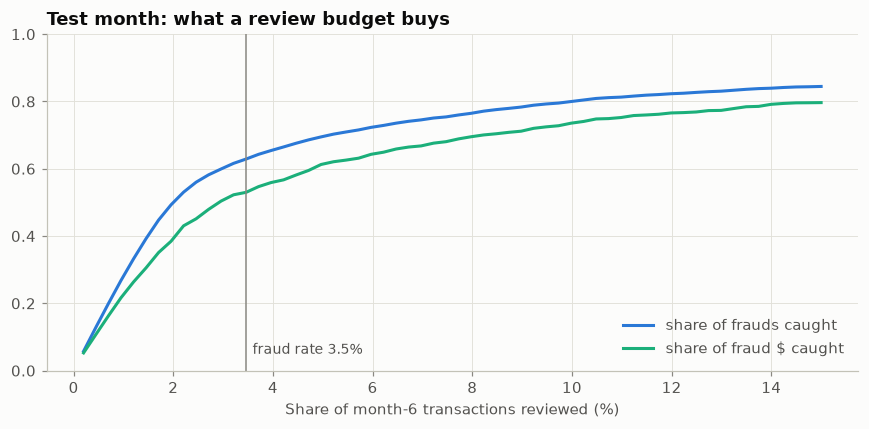

In [10]:
order_te = np.argsort(-test_final)
amt_te = meta.TransactionAmt.values[TE]
rates = np.linspace(0.002, 0.15, 60)
share_n = [y_te[order_te[:int(r * len(y_te))]].sum() / y_te.sum() for r in rates]
share_amt = [(amt_te * y_te)[order_te[:int(r * len(y_te))]].sum() / (amt_te * y_te).sum() for r in rates]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rates * 100, share_n, color=SERIES[0], label="share of frauds caught")
ax.plot(rates * 100, share_amt, color=SERIES[2], label="share of fraud $ caught")
ax.axvline(y_te.mean() * 100, color=MUTED, lw=1)
ax.annotate(f"fraud rate {y_te.mean():.1%}", (y_te.mean() * 100, 0.05), xytext=(4, 0),
            textcoords="offset points", color=INK_2, fontsize=9)
ax.set_xlabel("Share of month-6 transactions reviewed (%)"); ax.set_ylim(0, 1)
ax.set_title("Test month: what a review budget buys")
ax.legend(loc="lower right")
finish(fig)

## 6. How fast does a model go stale?

Fraud patterns, browsers, merchants and devices all change. We train LightGBM on data
up to day 60, 90, 120 and 150, freeze each model, and score every later 15-day window.
The fixed round count comes from early stopping above. Frequency encodings here use the
training-period fit for simplicity.

In [11]:
windows = np.arange(60, 183, 15)
decay = []
for cutoff in [60, 90, 120, 150]:
    n_cut = int((meta.day < cutoff).sum())
    m = lgb.train({k: v for k, v in LGB_PARAMS.items() if k != "metric"},
                  lgb.Dataset(X[:n_cut, :NF], y[:n_cut], feature_name=FEATURES, categorical_feature=CAT),
                  fitted["LightGBM"].best_iteration)
    for a in windows[windows >= cutoff]:
        rows_w = ((meta.day >= a) & (meta.day < a + 15)).values
        if rows_w.sum() < 1000:
            continue
        decay.append({"trained up to day": cutoff, "window start": a,
                      "days since training": a - cutoff,
                      "PR-AUC": average_precision_score(y[rows_w], m.predict(X[rows_w, :NF]))})
    del m
    ieee.release_memory()
decay = pd.DataFrame(decay)
decay.pivot(index="window start", columns="trained up to day", values="PR-AUC")

trained up to day,60,90,120,150
window start,,,,
60,0.7643,NaN,NaN,NaN
75,0.6329,NaN,NaN,NaN
90,0.5764,0.6568,NaN,NaN
105,0.6253,0.6651,NaN,NaN
120,0.6359,0.6756,0.7803,NaN
135,0.5126,0.5761,0.6393,NaN
150,0.5810,0.6111,0.6326,0.7275
165,0.5613,0.5910,0.6002,0.6511
180,0.5622,0.6170,0.6163,0.6704


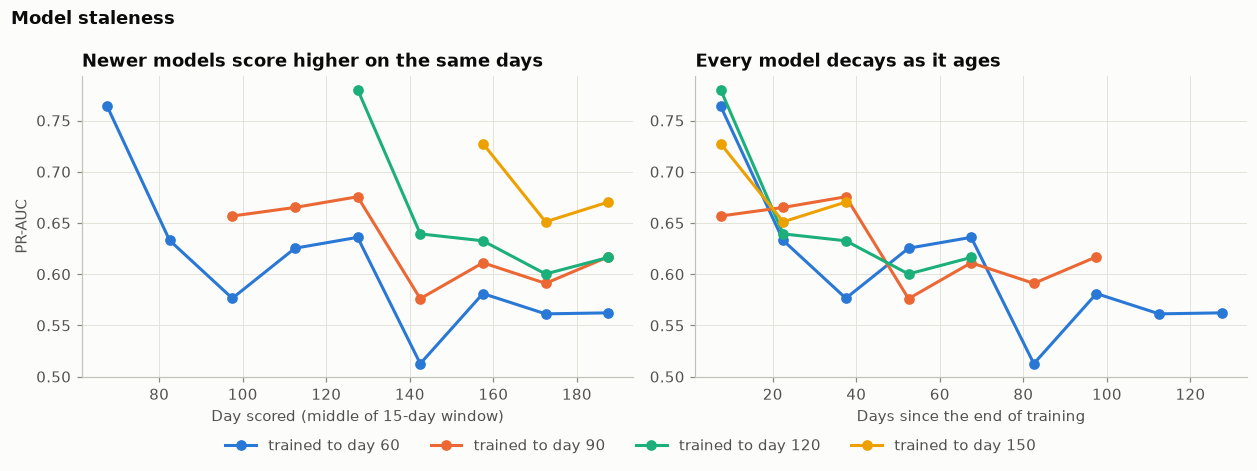

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for color, (cutoff, g) in zip(SERIES, decay.groupby("trained up to day")):
    axes[0].plot(g["window start"] + 7.5, g["PR-AUC"], marker="o", color=color, label=f"trained to day {cutoff}")
    axes[1].plot(g["days since training"] + 7.5, g["PR-AUC"], marker="o", color=color)
axes[0].set_xlabel("Day scored (middle of 15-day window)"); axes[0].set_ylabel("PR-AUC")
axes[0].set_title("Newer models score higher on the same days")

axes[1].set_xlabel("Days since the end of training")
axes[1].set_title("Every model decays as it ages")
fig.suptitle("Model staleness", x=0.01, ha="left", fontweight="bold")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncols=4, bbox_to_anchor=(0.5, -0.06))
finish(fig)

**Reading it.** Two patterns are clear despite the noise of 15-day windows:
* **Three of the four models score best in their first two weeks** (PR-AUC 0.73–0.78)
  and lose 0.08–0.14 over the next 15 days. The fall is steepest right after training
  ends. (The day-90 model is the exception: its first weeks happened to be harder.)
* **On almost any given day, the most recently trained model wins.** In month 6, the
  model trained to day 150 beats the one trained to day 120 by 0.05–0.10, consistent with
  the +0.07 gap in the test-month table.
* Some windows (days 135–150) are hard for every model. That is the fraud mix changing,
  not just the model aging.

**Recommendation:** retrain at least monthly, and ideally every one to two weeks. The
confirmed-fraud feature also needs fresh labels to stay useful (notebook 02).

## 7. Explaining the final model with SHAP

As in project 1, `TreeExplainer` splits each prediction (in log-odds) into per-feature
contributions. The difference here is that the top features have names an analyst can
reason about. We explain a sample of 4,000 test transactions, every fraud among them
included.

In [13]:
rng = np.random.default_rng(SEED)
te_idx = np.r_[rng.choice(np.where(y_te == 1)[0], 1000, replace=False),
               rng.choice(np.where(y_te == 0)[0], 3000, replace=False)]
X_shap = pd.DataFrame(X[TE][:, FINAL_COLS][te_idx], columns=FEATURES)
explainer = shap.TreeExplainer(final)
sv = explainer(X_shap)
if sv.values.ndim == 3:   # some versions return one slice per class
    sv = sv[..., 1]
# Show category names instead of integer codes in the plots.
display = X_shap.astype(object)
for c, names in CAT_NAMES.items():
    codes = X_shap[c].values
    display[c] = [names[int(v)] if not np.isnan(v) else "missing" for v in codes]
sv.display_data = display.values

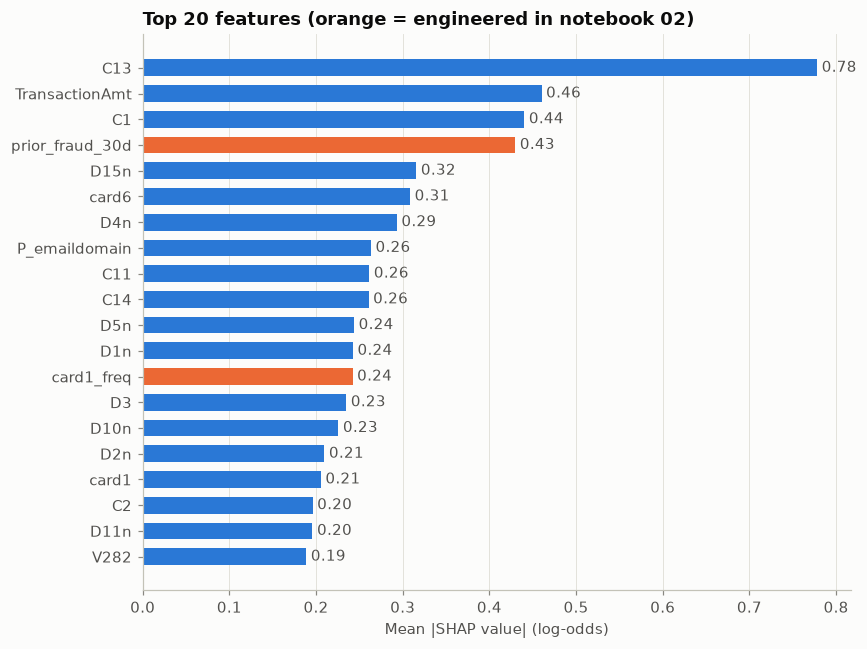

In [14]:
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).nlargest(20)[::-1]
engineered = {f for f in FEATURES if f.endswith("_freq") or f.startswith("prior_fraud")}
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(mean_abs.index, mean_abs.values, height=0.65,
               color=[SERIES[1] if f in engineered else SERIES[0] for f in mean_abs.index])
label_bars(ax, bars, fmt="{:.2f}", horizontal=True)
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("Top 20 features (orange = engineered in notebook 02)")
ax.grid(axis="y", visible=False)
finish(fig)

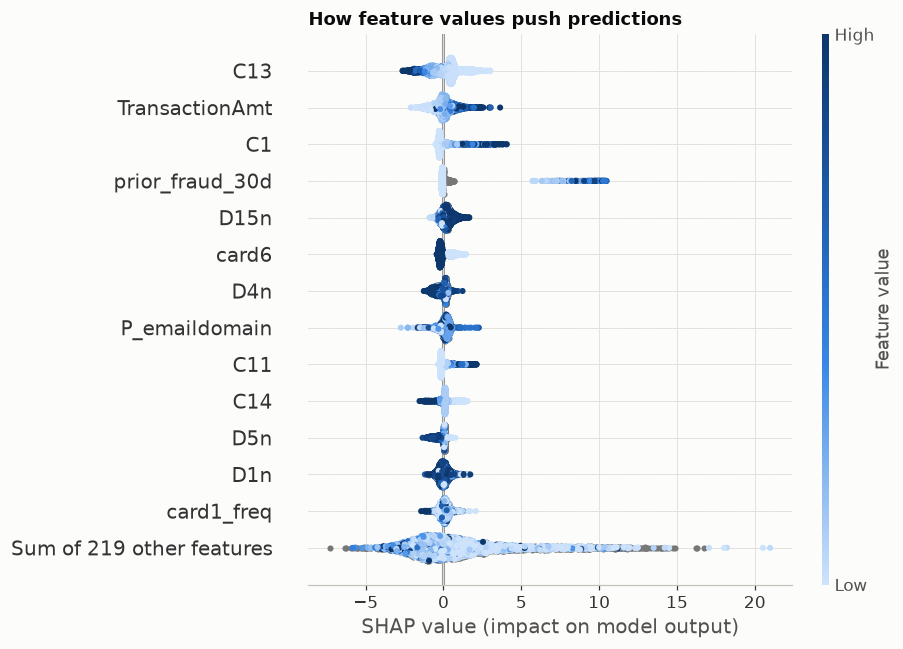

In [15]:
plt.figure()
shap.plots.beeswarm(sv, max_display=14, show=False, color=SEQUENTIAL)
plt.gca().set_title("How feature values push predictions", loc="left", fontweight="bold")
plt.gcf().set_size_inches(8.5, 6)
finish()

**Reading it.**
* **`C13`**, a count of something linked to the card (masked by Vesta): low counts push
  towards fraud. New or rarely seen cards are riskier, a theme throughout this project.
* **`TransactionAmt`**: larger amounts push towards fraud, while very small amounts are
  safe here (unlike project 1's card testing).
* **`C1`**: another masked count (Vesta's examples for C columns include "addresses
  linked to the card"). High values push towards fraud.
* **`prior_fraud_30d`**: zero for almost everyone, but a confirmed earlier fraud adds
  **+6 to +10 log-odds**, the largest single push in the model. Grey points are users
  the ID proxy couldn't identify.
* **`card6`**: credit cards push towards fraud, as in notebook 01's rate chart.

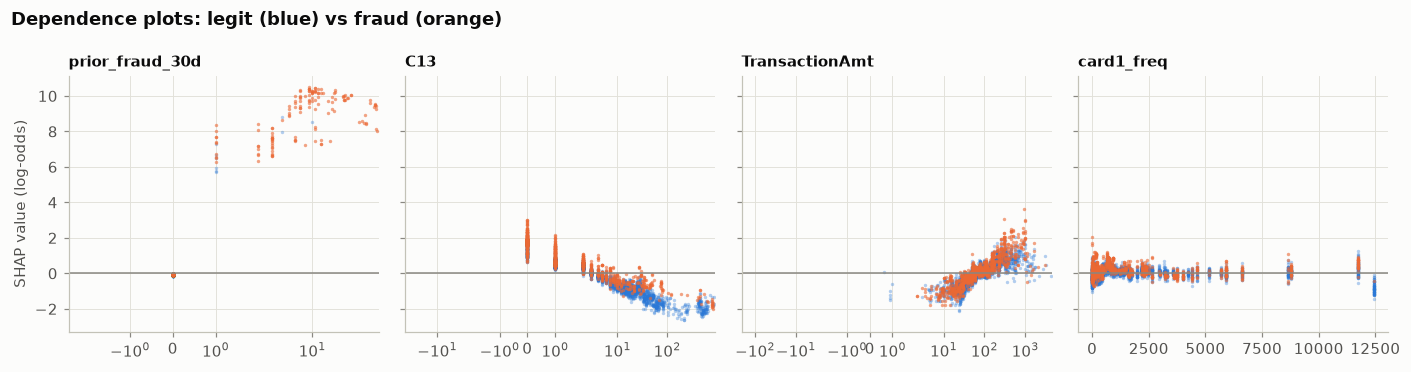

In [16]:
dep = ["prior_fraud_30d", "C13", "TransactionAmt", "card1_freq"]
dep = [d for d in dep if d in FEATURES][:4]
fig, axes = plt.subplots(1, len(dep), figsize=(3.2 * len(dep), 3.4), sharey=True)
is_fraud = y_te[te_idx] == 1
for ax, f in zip(np.atleast_1d(axes), dep):
    j = FEATURES.index(f)
    xv = sv.data[:, j]
    for c, msk in [(0, ~is_fraud), (1, is_fraud)]:
        ax.scatter(xv[msk], sv.values[msk, j], s=5, alpha=0.35 if c == 0 else 0.6, color=CLASS_COLORS[c])
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_title(f, fontsize=10)
    if np.nanmax(xv) > 50 * max(np.nanmedian(np.abs(xv)), 1):
        ax.set_xscale("symlog")
np.atleast_1d(axes)[0].set_ylabel("SHAP value (log-odds)")
fig.suptitle("Dependence plots: legit (blue) vs fraud (orange)", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.** The dependence plots turn those rankings into shapes:
* `prior_fraud_30d` is a step function. One confirmed fraud already adds about +6
  log-odds, and more add a little more.
* `C13` falls steadily on a log scale. Each tenfold increase in the count lowers risk.
* `TransactionAmt` rises from about $50 upwards.
* `card1_freq` is mostly flat, with lower risk for the very common card codes (the
  cluster at ~12,500), i.e. mainstream issuers.

### One alert, explained

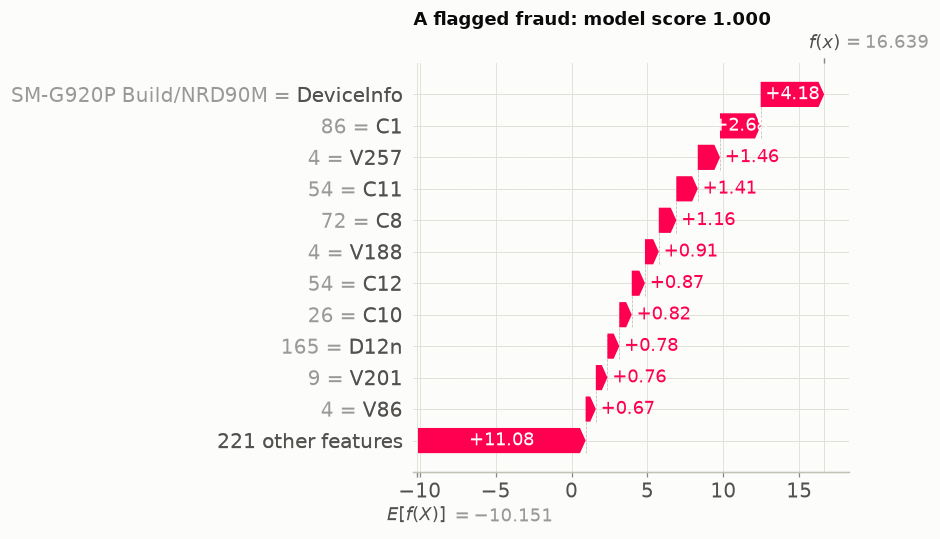

In [17]:
p_sample = final.predict(X_shap.values)
caught = int(np.argmax(np.where(is_fraud, p_sample, -1)))
plt.figure()
shap.plots.waterfall(sv[caught], max_display=12, show=False)
plt.gcf().set_size_inches(8.5, 5)
plt.title(f"A flagged fraud: model score {p_sample[caught]:.3f}", loc="left", fontweight="bold")
finish()

## 8. Summary

| Question | Answer |
|---|---|
| Calendar leakage? | `D3n` was a disguised date; keeping D3 raw costs nothing on the next month. |
| Which library? | LightGBM: best PR-AUC (0.722 on month 5) and fastest. The others weren't tuned as carefully. |
| Blend? | No gain (−0.002, not significant); one model is simpler to run and explain. |
| Final performance (month 6) | **PR-AUC 0.687** (95 % CI 0.671–0.700), ROC-AUC 0.938. 50 % of fraud caught when 2 % of transactions are reviewed, 70 % at 5 %. |
| Value of retraining | +0.07 PR-AUC from adding month 5 to the training data. Fresh models lose 0.08–0.14 within 15–30 days. |
| What drives decisions? | Card-linked counts (`C13`, `C1`), amount, confirmed earlier fraud, card type, account dates. |

**Project-level lessons** (notebooks 01–03):
1. **Validate on the future.** Every decision here (features, D handling, library) was
   made on a later month, and the test month was opened once.
2. **Test transformations; don't trust intuition.** Normalising D columns looked like a
   drift fix, increased drift (notebook 01), yet helped performance (notebook 02), except
   for D3, where it only created a disguised calendar (this notebook).
3. **The best features came from understanding the labels.** The user ID and the
   label-delay-aware confirmed-fraud count beat everything else engineered.
4. **Leakage and staleness are the two silent killers.** Leaky aggregates inflated
   validation by +0.03, and a month of staleness costs about as much as all the feature
   engineering gained.

**Limitations.** Masked features limit interpretation (`C13` is "some count"). Vesta's
test set has no labels, so the final evaluation uses one month (~3,300 frauds). Only
LightGBM was tuned. The ID proxy misses 11 % of rows.

**Comparison with the Kaggle leaderboard.** Top competition scores (ROC-AUC ≈ 0.96) are
not comparable. They were measured on a different, later period, and many top solutions
computed user aggregates over train *and* test together, the transductive approach that
notebook 02 showed to be leakage in a real deployment.